<a href="https://colab.research.google.com/github/KL-Mithunvel/AI/blob/main/CNN1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import cv2
import shutil

input_dir = "/content/drive/MyDrive/PROCESSED_DATA"
output_dir = "/content/ProcessedTiles_Grey"

# Clear old folder if exists
if os.path.exists(output_dir):
    shutil.rmtree(output_dir)
os.makedirs(output_dir, exist_ok=True)

for cls in os.listdir(input_dir):
    cls_path = os.path.join(input_dir, cls)
    if not os.path.isdir(cls_path):
        continue

    out_cls_path = os.path.join(output_dir, cls)
    os.makedirs(out_cls_path, exist_ok=True)

    for img_name in os.listdir(cls_path):
        img_path = os.path.join(cls_path, img_name)
        img = cv2.imread(img_path)
        if img is None:
            continue

        # Convert to grayscale
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        # Apply CLAHE to enhance contrast
        clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8,8))
        enhanced = clahe.apply(gray)

        # High-pass filter (sharpen cracks)
        blurred = cv2.GaussianBlur(enhanced, (5,5), 0)
        highpass = cv2.addWeighted(enhanced, 1.5, blurred, -0.5, 0)

        # Save grayscale crack-enhanced image
        out_path = os.path.join(out_cls_path, img_name)
        cv2.imwrite(out_path, highpass)

print("✅ Grayscale crack-enhanced dataset saved at:", output_dir)


✅ Grayscale crack-enhanced dataset saved at: /content/ProcessedTiles_Grey


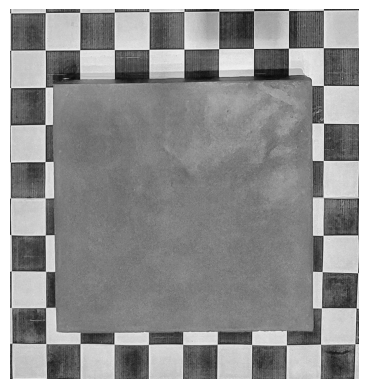

In [ ]:
import matplotlib.pyplot as plt

sample_img = os.path.join(out_cls_path, img_name)  # last processed image
img = cv2.imread(sample_img, cv2.IMREAD_GRAYSCALE)

plt.imshow(img, cmap="gray")
plt.axis("off")
plt.show()


In [ ]:
!pip install tensorflow opencv-python matplotlib

In [ ]:
!pip list

Package                               Version
------------------------------------- ------------------
absl-py                               1.4.0
absolufy-imports                      0.3.1
accelerate                            1.10.1
aiofiles                              24.1.0
aiohappyeyeballs                      2.6.1
aiohttp                               3.12.15
aiosignal                             1.4.0
alabaster                             1.0.0
albucore                              0.0.24
albumentations                        2.0.8
ale-py                                0.11.2
alembic                               1.16.5
altair                                5.5.0
annotated-types                       0.7.0
antlr4-python3-runtime                4.9.3
anyio                                 4.10.0
anywidget                             0.9.18
argon2-cffi                           25.1.0
argon2-cffi-bindings                  25.1.0
array_record                          0.8.1
arrow 

In [ ]:
import tensorflow as tf
import os

In [ ]:
gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

In [ ]:
tf.config.list_physical_devices('GPU')

[]

In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.19.0
GPUs: []


In [ ]:
import cv2
import imghdr

In [ ]:
!pwd

/content


In [ ]:
data_dir = '/content/ProcessedTiles_Grey'

In [ ]:
image_exts = ['jpeg','jpg', 'bmp', 'png']

In [ ]:
for image_class in os.listdir(data_dir):
    for image in os.listdir(os.path.join(data_dir, image_class)):
        image_path = os.path.join(data_dir, image_class, image)
        try:
            img = cv2.imread(image_path)
            tip = imghdr.what(image_path)
            if tip not in image_exts:
                print('Image not in ext list {}'.format(image_path))
                os.remove(image_path)
        except Exception as e:
            print('Issue with image {}'.format(image_path))

In [ ]:
import numpy as np
from matplotlib import pyplot as plt

In [ ]:
data = tf.keras.utils.image_dataset_from_directory('/content/ProcessedTiles_Grey',color_mode='grayscale',      # 🔥 force grayscale (1 channel)
    image_size=(256,256),
    batch_size=32
)

Found 328 files belonging to 4 classes.


In [ ]:
data_iterator = data.as_numpy_iterator()
batch = data_iterator.next()

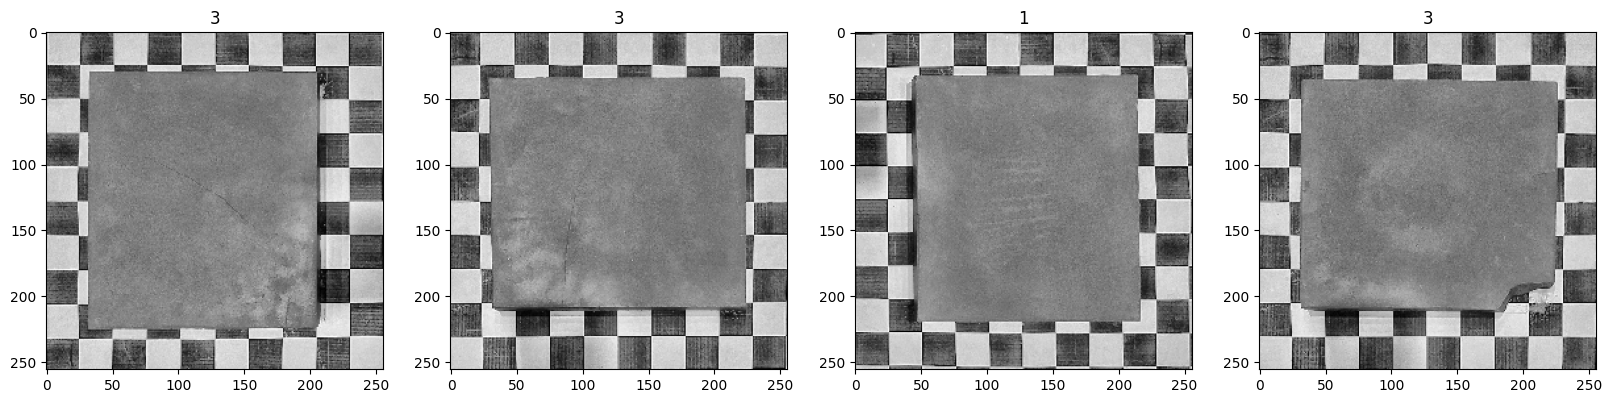

In [ ]:
fig, ax = plt.subplots(ncols=4, figsize=(20,20))
for idx, img in enumerate(batch[0][:4]):
    ax[idx].imshow(img.squeeze().astype("uint8"), cmap='gray', vmin=0, vmax=255)
    ax[idx].title.set_text(batch[1][idx])




In [ ]:
print(batch[0].min(), batch[0].max(), batch[0].dtype)


0.0 255.0 float32


In [ ]:
data = data.map(lambda x,y: (x/255, y))
data.as_numpy_iterator().next()

(array([[[[0.6878523 ],
          [0.6912871 ],
          [0.67301947],
          ...,
          [0.8472223 ],
          [0.0448311 ],
          [0.30140874]],
 
         [[0.8302694 ],
          [0.7957423 ],
          [0.7358141 ],
          ...,
          [0.8717491 ],
          [0.0421688 ],
          [0.24804886]],
 
         [[0.8143146 ],
          [0.80019253],
          [0.69517356],
          ...,
          [0.88467586],
          [0.03113511],
          [0.24213125]],
 
         ...,
 
         [[0.31696254],
          [0.60103226],
          [0.7389958 ],
          ...,
          [0.83475137],
          [0.03898022],
          [0.47985733]],
 
         [[0.10906435],
          [0.60678786],
          [0.93016803],
          ...,
          [0.88598937],
          [0.03233933],
          [0.54962635]],
 
         [[0.7121119 ],
          [0.68829995],
          [0.27614912],
          ...,
          [0.90068275],
          [0.03885088],
          [0.54530436]]],
 
 
        [

In [ ]:
# 5. Split Data (no change, just confirm counts)
dataset_size = len(data)
train_size = int(0.7 * dataset_size)
val_size   = int(0.2 * dataset_size)
test_size  = int(0.1 * dataset_size)

train = data.take(train_size)
val   = data.skip(train_size).take(val_size)
test  = data.skip(train_size+val_size).take(test_size)


In [ ]:
train_size = int(len(data)*.7)
val_size = int(len(data)*.2)
test_size = int(len(data)*.1)
train_size

7

In [ ]:
train = data.take(train_size)
val = data.skip(train_size).take(val_size)
test = data.skip(train_size+val_size).take(test_size)

In [ ]:
train

<_TakeDataset element_spec=(TensorSpec(shape=(None, 256, 256, 1), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>

In [ ]:

from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', padding='same', input_shape=(256,256,1)),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(128, (3,3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(256, (3,3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(512, (3,3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2,2),

    layers.Flatten(),
    layers.Dense(512, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(4, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

model.summary()



Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_15 (Conv2D)              │ (None, 256, 256, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 256, 256, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 128, 128, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 128, 128, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 64, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 32, 32, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 32, 32, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 16, 16, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 16, 16, 512)    │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 512)            │    16,777,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 4)              │         2,052 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,351,748 (70.01 MB)

 Trainable params: 18,349,764 (70.00 MB)

 Non-trainable params: 1,984 (7.75 KB)

In [ ]:
logdir='logs'

In [ ]:
tensorboard_callback = tf.keras.callbacks.TensorBoard(log_dir=logdir)

In [ ]:
hist = model.fit(train, epochs=50, validation_data=val, callbacks=[tensorboard_callback])


Epoch 1/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 92s 13s/step - accuracy: 0.6937 - loss: 0.6629 - val_accuracy: 0.2188 - val_loss: 185.8301
Epoch 2/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 89s 13s/step - accuracy: 0.6641 - loss: 0.6471 - val_accuracy: 0.2969 - val_loss: 157.3118
Epoch 3/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 90s 13s/step - accuracy: 0.5612 - loss: 0.7652 - val_accuracy: 0.1875 - val_loss: 195.2466
Epoch 4/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 142s 13s/step - accuracy: 0.6110 - loss: 0.7789 - val_accuracy: 0.2656 - val_loss: 167.7593
Epoch 5/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 90s 13s/step - accuracy: 0.6817 - loss: 0.6901 - val_accuracy: 0.2031 - val_loss: 182.0332
Epoch 6/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 89s 13s/step - accuracy: 0.6864 - loss: 0.6042 - val_accuracy: 0.2656 - val_loss: 170.1461
Epoch 7/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 90s 13s/step - accuracy: 0.6240 - loss: 0.7322 - val_accuracy: 0.2969 - val_loss: 159.9604
Epoch 8/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 90s 13s/step - accuracy: 0.7365 - loss: 0.5436 - val_accuracy: 0.1719 - va